<a href="https://colab.research.google.com/github/HeyWinTomsy/MN/blob/main/%D0%9B%D0%A04_%D0%90%D0%BD%D1%82%D1%80%D0%BE%D0%BF%D0%BE%D0%B2%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


Я був присутній на парі


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [9]:
import pandas as pd
import zipfile
from google.colab import files

uploaded = files.upload()
zip_name = next(iter(uploaded))

with zipfile.ZipFile(zip_name, 'r') as archive:
    with archive.open('CarPrice_Assignment.csv') as file:
        df = pd.read_csv(file)

display(df.head())

print("Кількість об'єктів:", df.shape[0])
print("Кількість ознак:", df.shape[1])

print(df.columns.tolist())

df.info()

target = "price"

print("Цільова змінна:", target)
print("Тип даних:", df[target].dtype)
print("Кількість унікальних значень:", df[target].nunique())

display(df.describe(include="all"))

print(df.isnull().sum())

Saving archive (2).zip to archive (2) (4).zip


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


Кількість об'єктів: 205
Кількість ознак: 26
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 205 entries, 0 to 204
Data columns (total 26 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   car_ID            205 non-null    int64  
 1   symboling         205 non-null    int64  
 2   CarName           205 non-null    object 
 3   fueltype          205 non-null    object 
 4   aspiration        205 non-null    object 
 5   doornumber        205 non-null    object 
 6   carbody           205 non-null    object 
 7   drivewheel        205 non-null    object 
 8   enginelocation    205 non-null 

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205,205,205,205,205,205,205,205.000000,...,205.000000,205,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
unique,NaN,NaN,147,2,2,2,5,3,2,NaN,...,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,peugeot 504,gas,std,four,sedan,fwd,front,NaN,...,NaN,mpfi,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,6,185,168,115,96,120,202,NaN,...,NaN,94,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,103.000000,0.834146,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.756585,...,126.907317,NaN,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.021776,...,41.642693,NaN,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86.600000,...,61.000000,NaN,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,94.500000,...,97.000000,NaN,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,97.000000,...,120.000000,NaN,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,102.400000,...,141.000000,NaN,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000


car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [10]:
print("=== Пропущені значення ===")
print(df.isnull().sum())
print("Усього пропущених:", df.isnull().sum().sum())

print("\n=== Змістові дублікати ===")
duplicates = df.drop(columns=["car_ID"]).duplicated()
print("Кількість дублікатів:", duplicates.sum())

print("\n=== Унікальні значення ===")
print(df.nunique())

print("\n=== Перевірка car_ID ===")
print("Кількість рядків:", len(df))
print("Унікальних ID:", df["car_ID"].nunique())

=== Пропущені значення ===
car_ID              0
symboling           0
CarName             0
fueltype            0
aspiration          0
doornumber          0
carbody             0
drivewheel          0
enginelocation      0
wheelbase           0
carlength           0
carwidth            0
carheight           0
curbweight          0
enginetype          0
cylindernumber      0
enginesize          0
fuelsystem          0
boreratio           0
stroke              0
compressionratio    0
horsepower          0
peakrpm             0
citympg             0
highwaympg          0
price               0
dtype: int64
Усього пропущених: 0

=== Змістові дублікати ===
Кількість дублікатів: 0

=== Унікальні значення ===
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44

## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [11]:
car_ids = df["car_ID"].copy()

print("Збережені ідентифікатори автомобілів:")
display(car_ids.head())

df = df.drop(columns=["car_ID"])

print("Стовпець car_ID видалено з датасету.")
print("Назви стовпців:")
print(df.columns.tolist())

print("Кількість збережених ID:", len(car_ids))
print("Чи залишився car_ID у датасеті:", "car_ID" in df.columns)

Збережені ідентифікатори автомобілів:


,car_ID
0,1
1,2
2,3
3,4
4,5


Стовпець car_ID видалено з датасету.
Назви стовпців:
['symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']
Кількість збережених ID: 205
Чи залишився car_ID у датасеті: False


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew

numeric_df = df.select_dtypes(include="number")

print("Числові ознаки:")
print(numeric_df.columns.tolist())

print("\nКількість числових ознак:", numeric_df.shape[1])

Числові ознаки:
['symboling', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Кількість числових ознак: 15


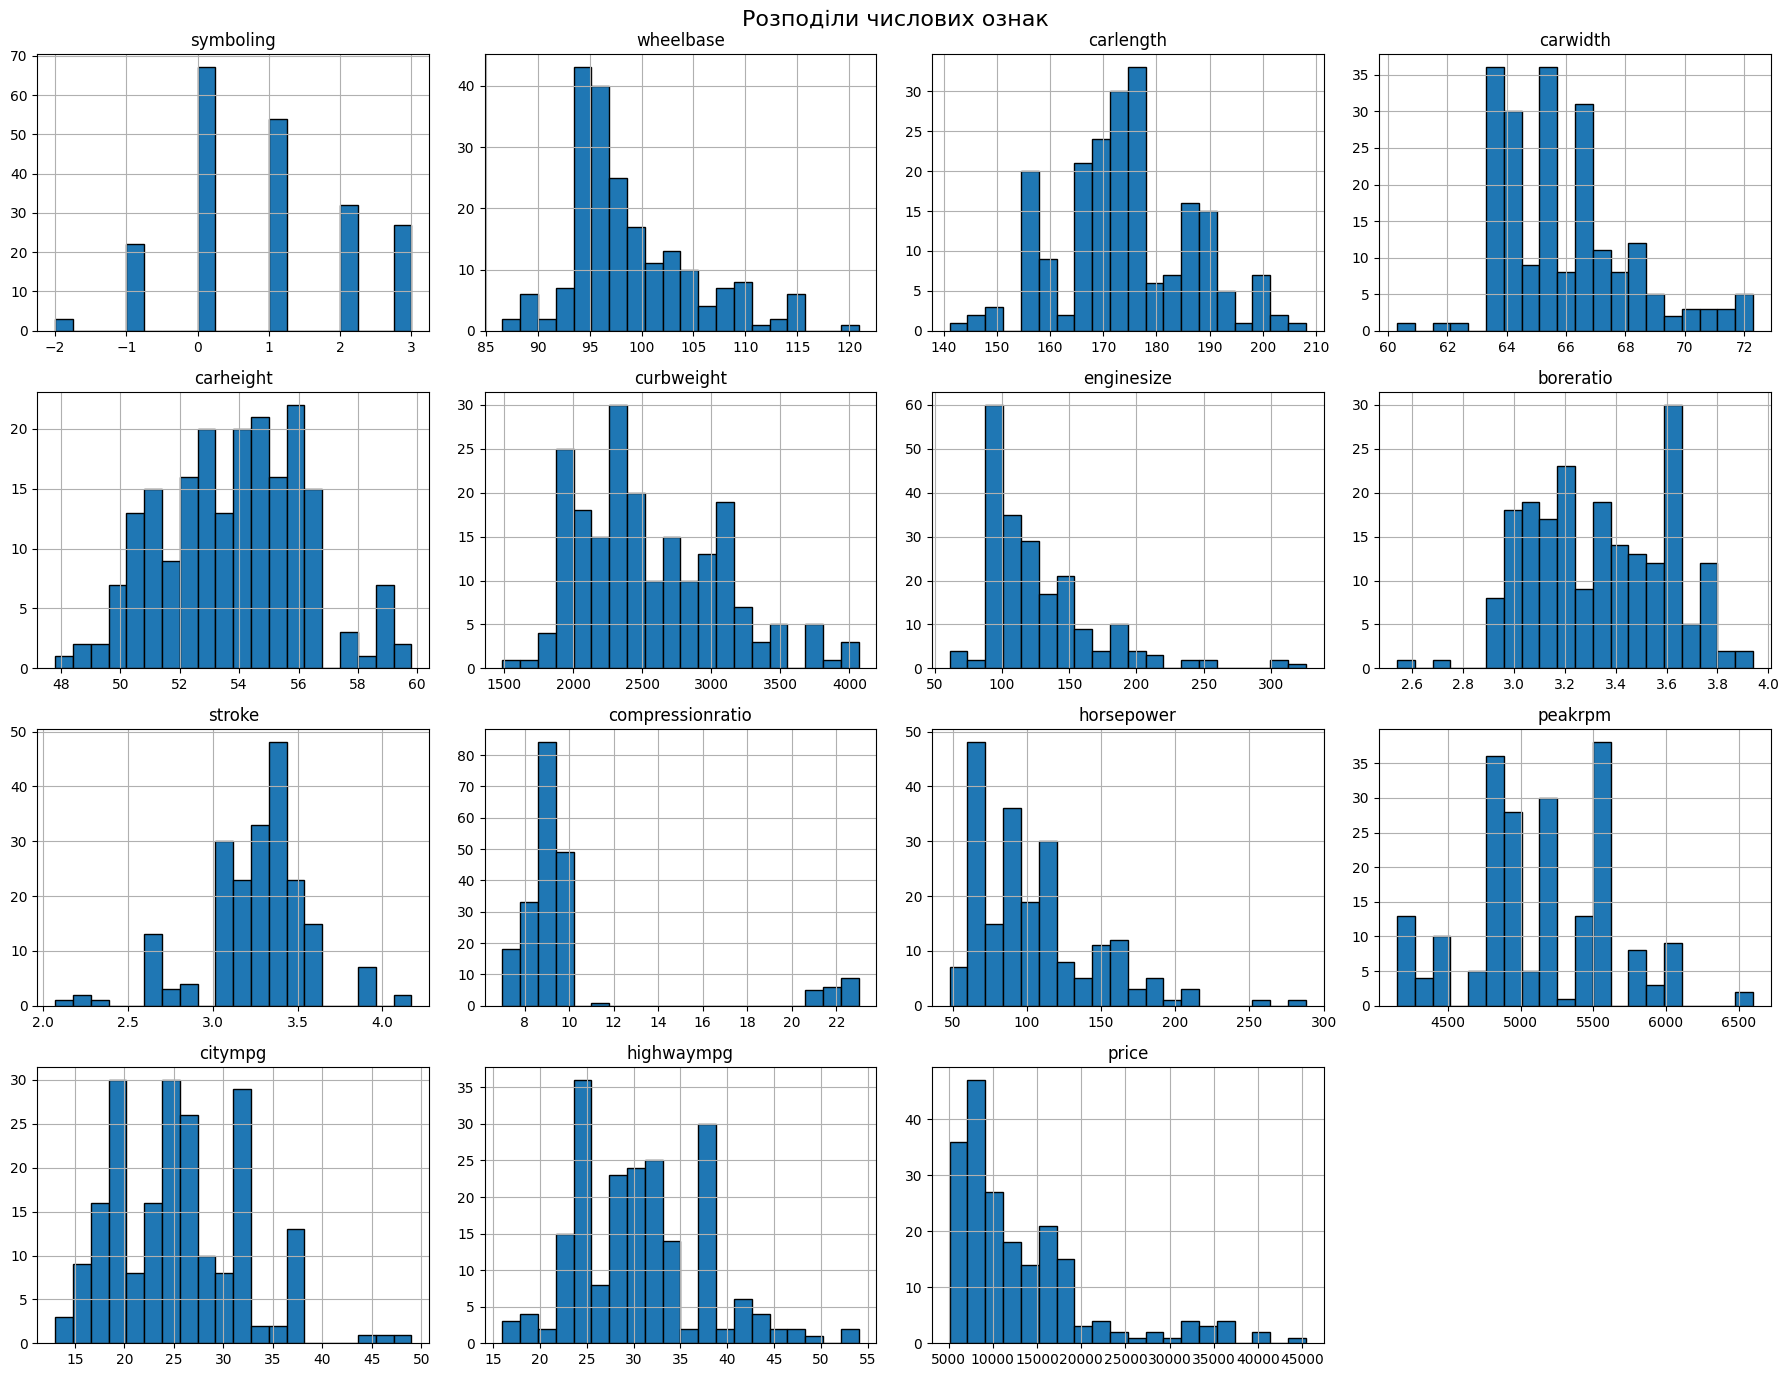

In [13]:
numeric_df.hist(
    bins=20,
    figsize=(18, 14),
    edgecolor="black"
)

plt.suptitle("Розподіли числових ознак", fontsize=16)
plt.tight_layout()
plt.show()

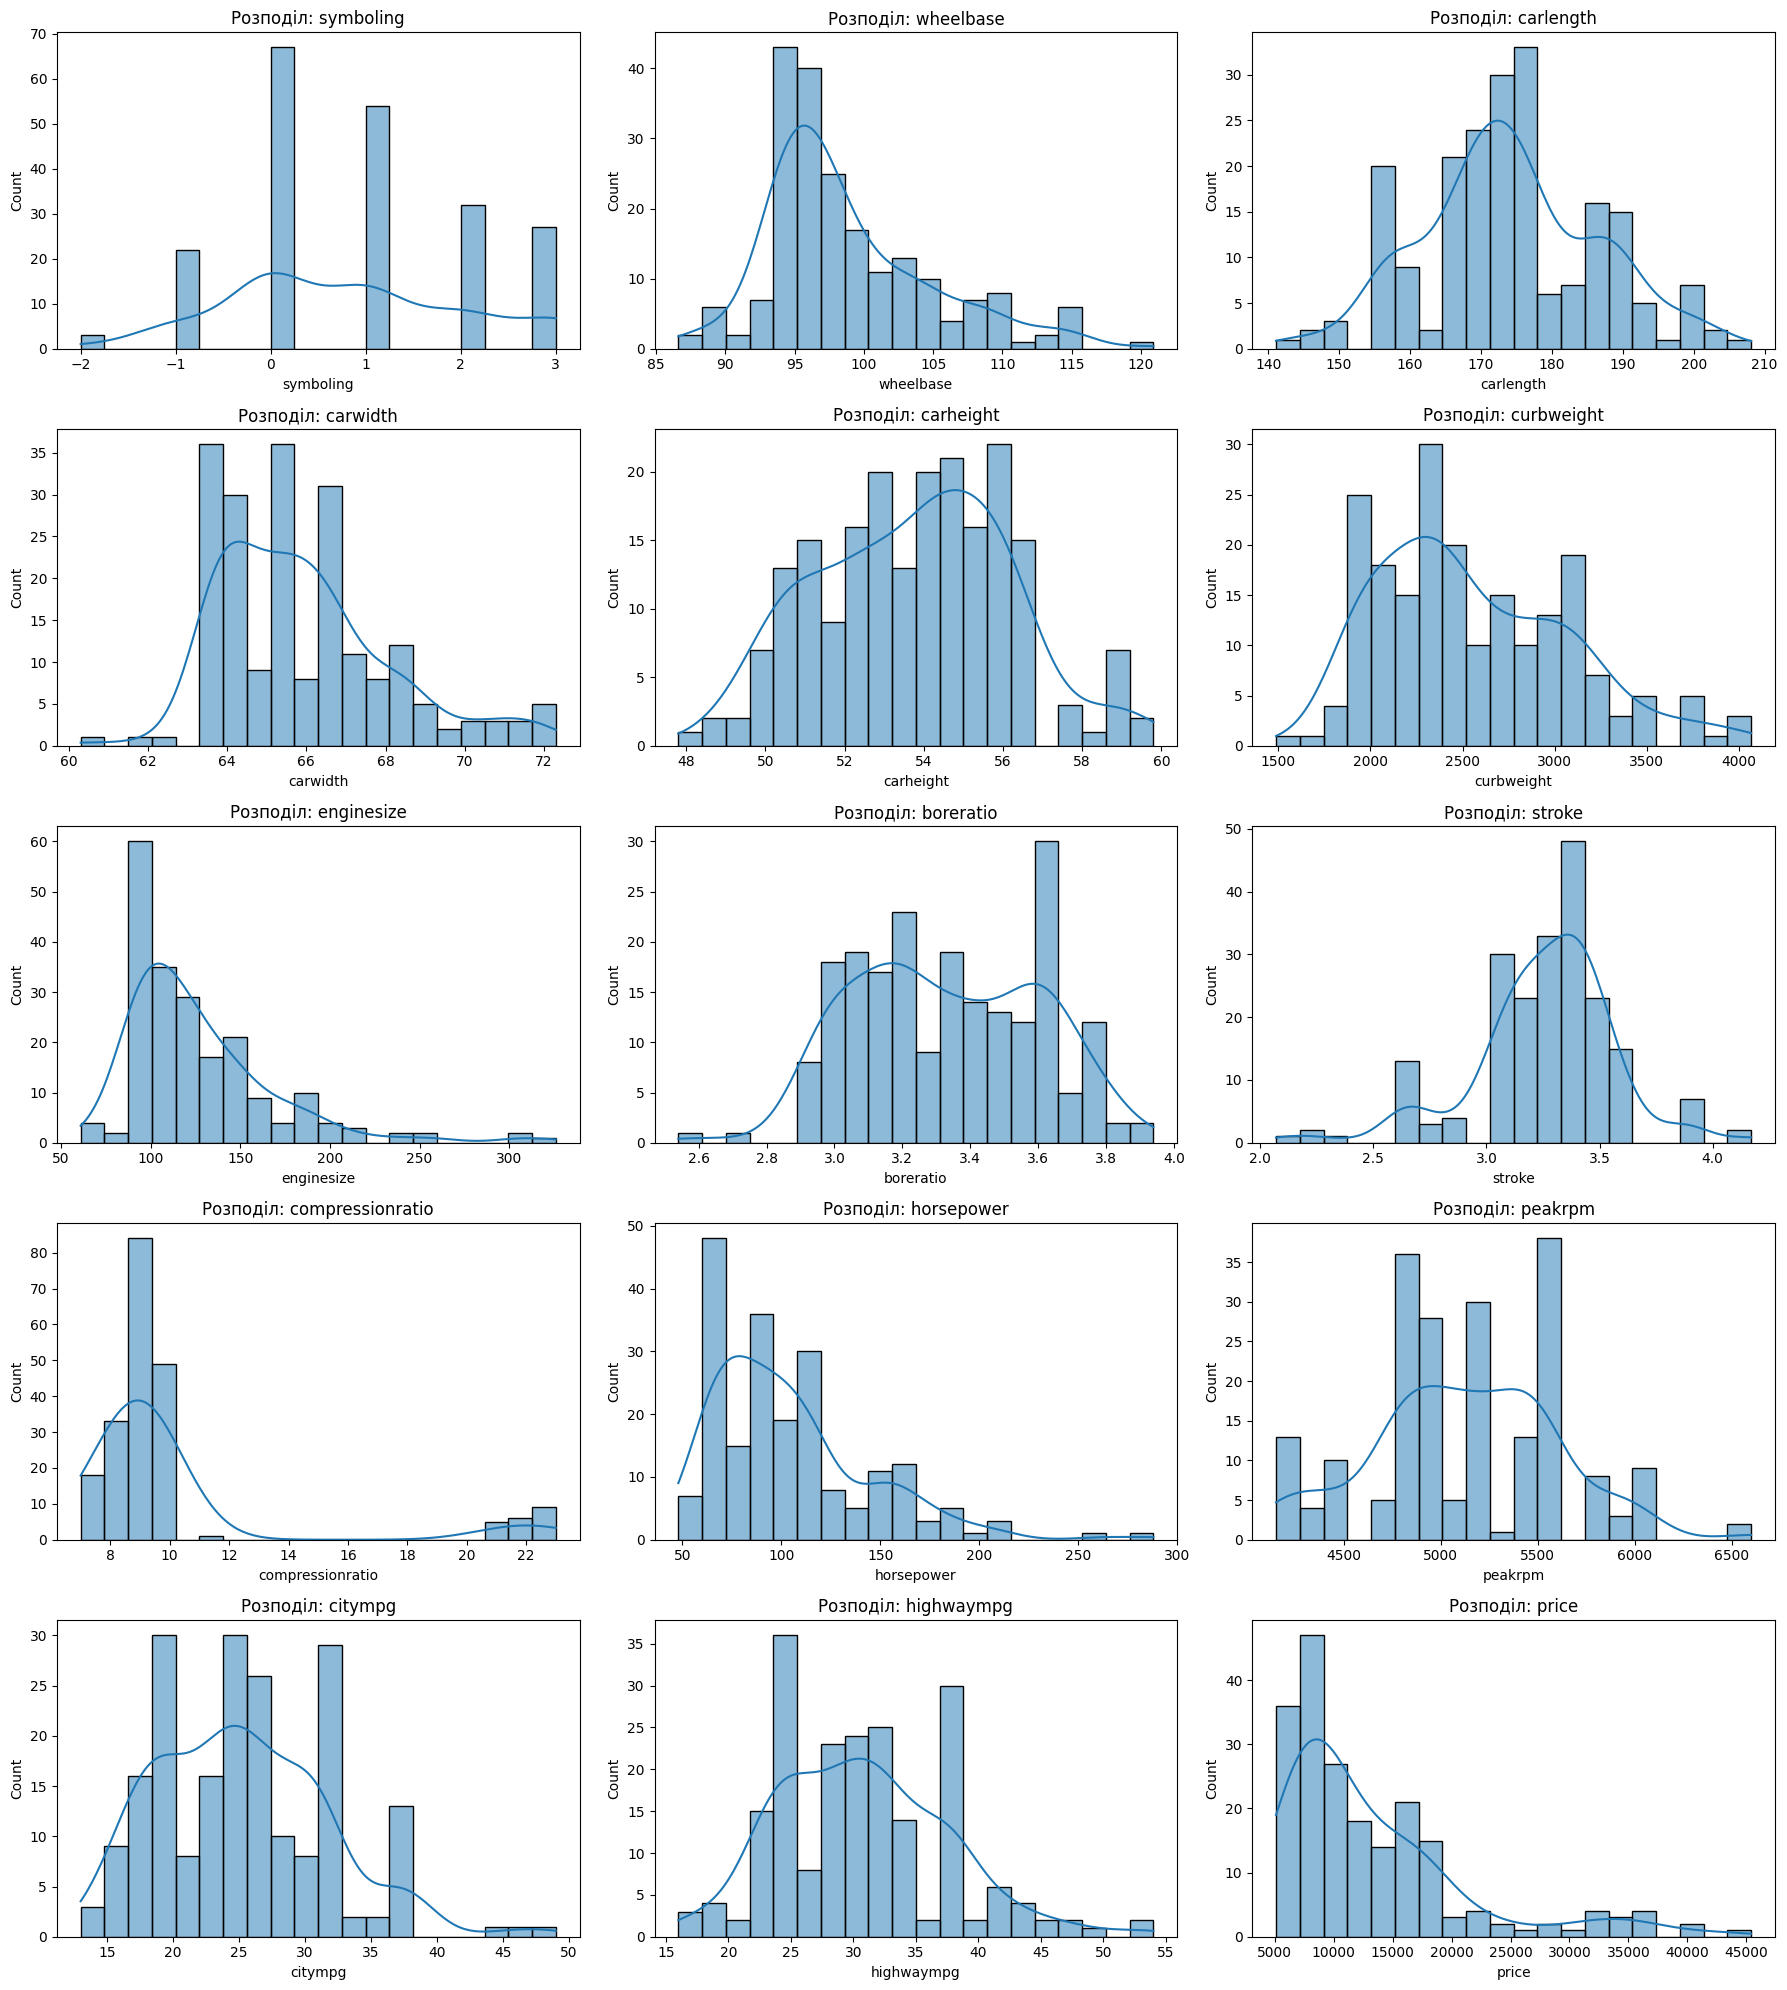

In [14]:
columns = numeric_df.columns

fig, axes = plt.subplots(
    nrows=(len(columns) + 2) // 3,
    ncols=3,
    figsize=(18, 4 * ((len(columns) + 2) // 3))
)

axes = axes.flatten()

for i, column in enumerate(columns):
    sns.histplot(
        data=numeric_df,
        x=column,
        kde=True,
        bins=20,
        ax=axes[i]
    )
    axes[i].set_title(f"Розподіл: {column}")

for i in range(len(columns), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()

In [15]:
skewness = numeric_df.skew().sort_values(
    key=lambda x: x.abs(),
    ascending=False
)

print("Коефіцієнти асиметрії:")
display(skewness.to_frame(name="Коефіцієнт асиметрії"))

Коефіцієнти асиметрії:


,Коефіцієнт асиметрії
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
stroke,-0.689705
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997


In [16]:
skewness_abs = skewness.abs().sort_values(ascending=False)

print("Топ-5 ознак із найбільш вираженою асиметрією:")
display(
    pd.DataFrame({
        "Коефіцієнт асиметрії": skewness.loc[skewness_abs.index].head(5),
        "Абсолютна асиметрія": skewness_abs.head(5)
    })
)

Топ-5 ознак із найбільш вираженою асиметрією:


,Коефіцієнт асиметрії,Абсолютна асиметрія
compressionratio,2.610862,2.610862
enginesize,1.947655,1.947655
price,1.777678,1.777678
horsepower,1.405310,1.405310
wheelbase,1.050214,1.050214


In [17]:
print("Аналіз асиметрії числових ознак:\n")

for column, value in skewness.items():
    if value > 1:
        result = "виражена правостороння асиметрія"
    elif value > 0.5:
        result = "помірна правостороння асиметрія"
    elif value < -1:
        result = "виражена лівостороння асиметрія"
    elif value < -0.5:
        result = "помірна лівостороння асиметрія"
    else:
        result = "асиметрія невелика"

    print(f"{column}: {value:.3f} — {result}")

Аналіз асиметрії числових ознак:

compressionratio: 2.611 — виражена правостороння асиметрія
enginesize: 1.948 — виражена правостороння асиметрія
price: 1.778 — виражена правостороння асиметрія
horsepower: 1.405 — виражена правостороння асиметрія
wheelbase: 1.050 — виражена правостороння асиметрія
carwidth: 0.904 — помірна правостороння асиметрія
stroke: -0.690 — помірна лівостороння асиметрія
curbweight: 0.681 — помірна правостороння асиметрія
citympg: 0.664 — помірна правостороння асиметрія
highwaympg: 0.540 — помірна правостороння асиметрія
symboling: 0.211 — асиметрія невелика
carlength: 0.156 — асиметрія невелика
peakrpm: 0.075 — асиметрія невелика
carheight: 0.063 — асиметрія невелика
boreratio: 0.020 — асиметрія невелика


## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [18]:
from sklearn.model_selection import train_test_split

y = df["price"]

X = df.drop(columns=["price"])

print("Кількість ознак:", X.shape[1])
print("Кількість цільових значень:", y.shape[0])

Кількість ознак: 24
Кількість цільових значень: 205


In [19]:
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X,
    y,
    car_ids,
    test_size=0.2,
    random_state=42
)

print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

print("\nНавчальні цільові значення:", y_train.shape)
print("Тестові цільові значення:", y_test.shape)

print("\nКількість ID у train:", len(id_train))
print("Кількість ID у test:", len(id_test))

Навчальна вибірка: (164, 24)
Тестова вибірка: (41, 24)

Навчальні цільові значення: (164,)
Тестові цільові значення: (41,)

Кількість ID у train: 164
Кількість ID у test: 41


In [20]:
print("Загальна кількість об'єктів:", len(df))
print("Об'єктів у train:", len(X_train))
print("Об'єктів у test:", len(X_test))

print("\nЧастка train:", round(len(X_train) / len(df) * 100, 2), "%")
print("Частка test:", round(len(X_test) / len(df) * 100, 2), "%")

print("\nЧи є спільні ID у train і test:",
      not set(id_train).isdisjoint(set(id_test)))

Загальна кількість об'єктів: 205
Об'єктів у train: 164
Об'єктів у test: 41

Частка train: 80.0 %
Частка test: 20.0 %

Чи є спільні ID у train і test: False


In [21]:
train_results = X_train.copy()
train_results.insert(0, "car_ID", id_train)
train_results["price"] = y_train

print("Приклади навчальної вибірки:")
display(train_results.head())

test_results = X_test.copy()
test_results.insert(0, "car_ID", id_test)
test_results["price"] = y_test

print("Приклади тестової вибірки:")
display(test_results.head())

Приклади навчальної вибірки:


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
66,67,0,mazda rx-7 gs,diesel,std,four,sedan,rwd,front,104.9,...,134,idi,3.43,3.64,22.0,72,4200,31,39,18344.0
111,112,0,peugeot 504,gas,std,four,sedan,rwd,front,107.9,...,120,mpfi,3.46,2.19,8.4,95,5000,19,24,15580.0
153,154,0,toyota corona hardtop,gas,std,four,wagon,fwd,front,95.7,...,92,2bbl,3.05,3.03,9.0,62,4800,31,37,6918.0
96,97,1,nissan latio,gas,std,four,sedan,fwd,front,94.5,...,97,2bbl,3.15,3.29,9.4,69,5200,31,37,7499.0
38,39,0,honda civic 1300,gas,std,two,hatchback,fwd,front,96.5,...,110,1bbl,3.15,3.58,9.0,86,5800,27,33,9095.0


Приклади тестової вибірки:


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
15,16,0,bmw x4,gas,std,four,sedan,rwd,front,103.5,...,209,mpfi,3.62,3.39,8.00,182,5400,16,22,30760.000
9,10,0,audi 5000s (diesel),gas,turbo,two,hatchback,4wd,front,99.5,...,131,mpfi,3.13,3.40,7.00,160,5500,16,22,17859.167
100,101,0,nissan nv200,gas,std,four,sedan,fwd,front,97.2,...,120,2bbl,3.33,3.47,8.50,97,5200,27,34,9549.000
132,133,3,saab 99e,gas,std,two,hatchback,fwd,front,99.1,...,121,mpfi,3.54,3.07,9.31,110,5250,21,28,11850.000
68,69,-1,buick century luxus (sw),diesel,turbo,four,wagon,rwd,front,110.0,...,183,idi,3.58,3.64,21.50,123,4350,22,25,28248.000


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [22]:
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()

continuous_cols = [col for col in numeric_cols if col != "symboling"]

outlier_bounds = {}
outlier_results = []

for col in continuous_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_bounds[col] = (lower, upper)

    count = ((X_train[col] < lower) | (X_train[col] > upper)).sum()

    outlier_results.append({
        "Ознака": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Нижня межа": lower,
        "Верхня межа": upper,
        "Кількість потенційних викидів": count
    })

outlier_summary = pd.DataFrame(outlier_results)
outlier_summary = outlier_summary.sort_values(
    "Кількість потенційних викидів",
    ascending=False
)

display(outlier_summary.round(2))


,Ознака,Q1,Q3,IQR,Нижня межа,Верхня межа,Кількість потенційних викидів
8,compressionratio,8.60,9.40,0.80,7.40,10.60,20
7,stroke,3.11,3.41,0.30,2.66,3.86,16
2,carwidth,64.18,66.68,2.50,60.42,70.42,10
9,horsepower,71.50,116.00,44.50,4.75,182.75,7
5,enginesize,98.00,141.00,43.00,33.50,205.50,7
0,wheelbase,94.50,102.10,7.60,83.10,113.50,6
10,peakrpm,4800.00,5500.00,700.00,3750.00,6550.00,2
12,highwaympg,25.00,34.00,9.00,11.50,47.50,1
6,boreratio,3.15,3.54,0.39,2.56,4.12,1
4,curbweight,2163.00,2939.25,776.25,998.62,4103.62,0


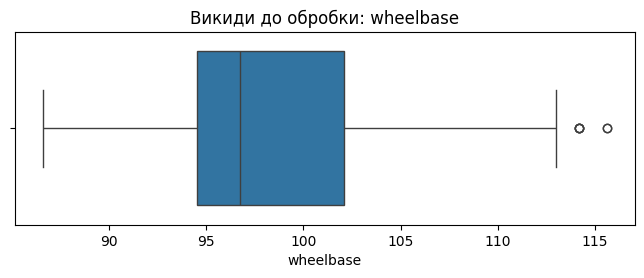

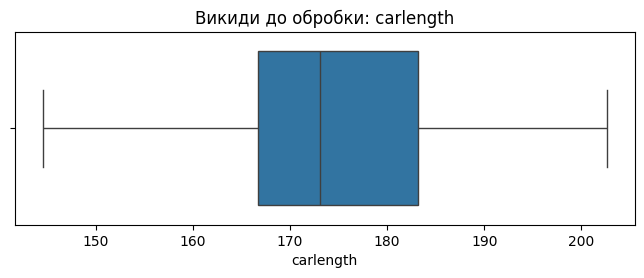

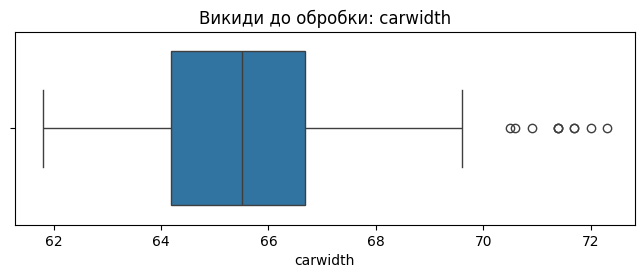

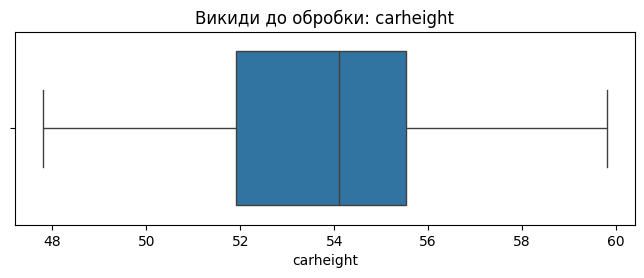

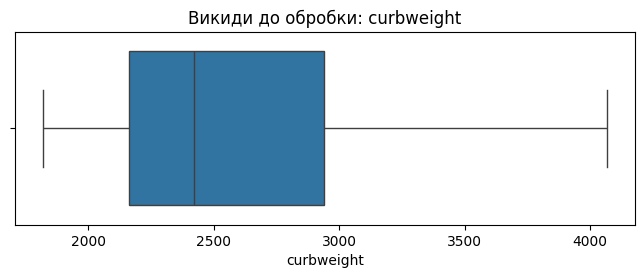

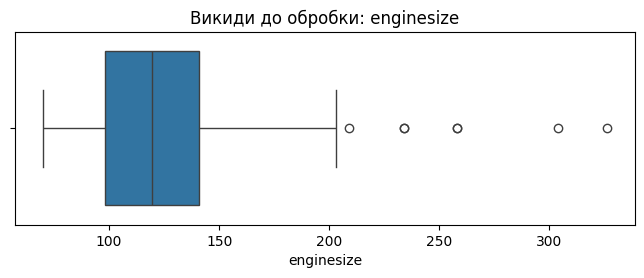

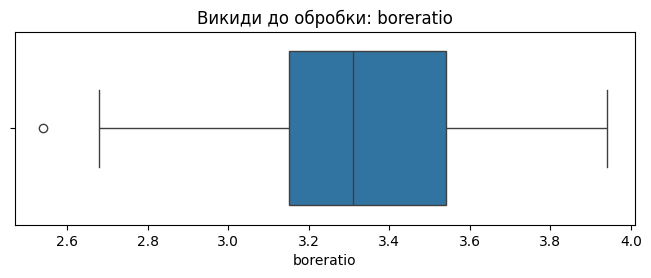

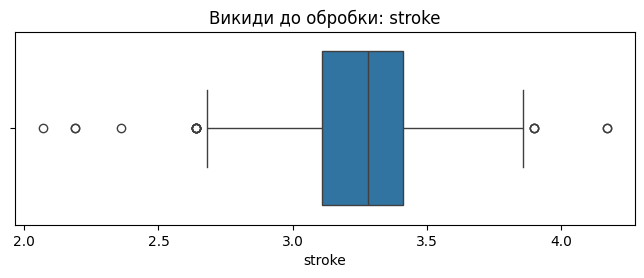

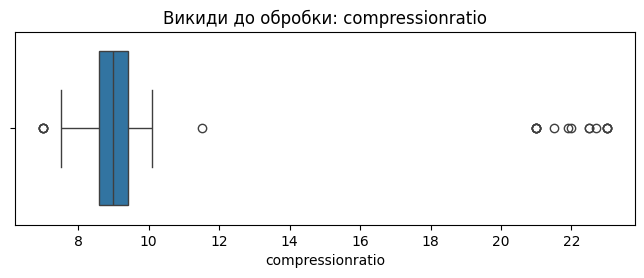

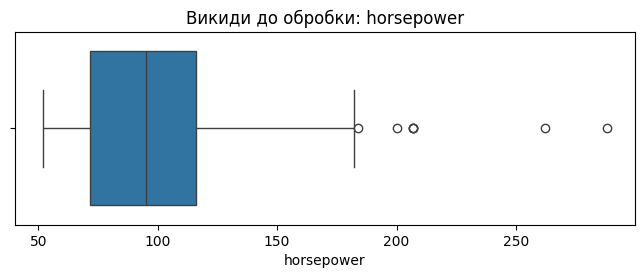

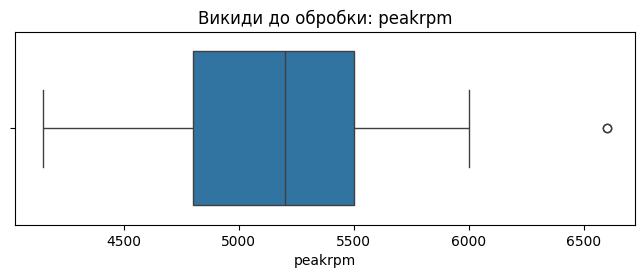

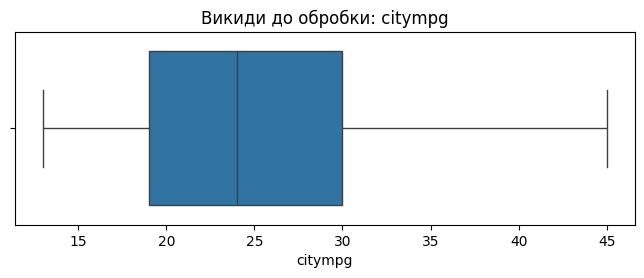

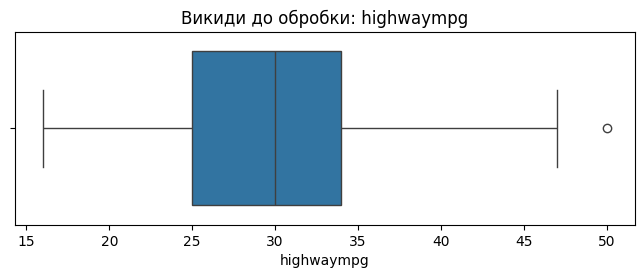

In [23]:

import matplotlib.pyplot as plt
import seaborn as sns

for col in continuous_cols:
    plt.figure(figsize=(8, 2.5))
    sns.boxplot(x=X_train[col])
    plt.title(f"Викиди до обробки: {col}")
    plt.xlabel(col)
    plt.show()


In [24]:
for col, (lower, upper) in outlier_bounds.items():
    X_train[col] = X_train[col].clip(lower=lower, upper=upper)
    X_test[col] = X_test[col].clip(lower=lower, upper=upper)

print("Обробку викидів завершено.")
print("Кількість рядків у train після обробки:", len(X_train))
print("Кількість рядків у test після обробки:", len(X_test))
print("Кількість ознак у train:", X_train.shape[1])
print("Кількість ознак у test:", X_test.shape[1])


Обробку викидів завершено.
Кількість рядків у train після обробки: 164
Кількість рядків у test після обробки: 41
Кількість ознак у train: 24
Кількість ознак у test: 24


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


In [31]:
import numpy as np
import pandas as pd

numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
continuous_cols = [col for col in numeric_cols if col != "symboling"]

corr_matrix = X_train[continuous_cols].corr()

print("Матриця кореляцій числових ознак:")
display(corr_matrix.round(2))

price_corr = X_train[continuous_cols].corrwith(y_train).abs()

print("Абсолютний зв'язок ознак із цільовою змінною price:")
display(
    price_corr.sort_values(ascending=False)
    .rename("|Кореляція з price|")
    .to_frame()
    .round(3)
)


Матриця кореляцій числових ознак:


,wheelbase,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,highwaympg
wheelbase,1.00,0.58,0.74,0.48,0.44,0.19,0.00,0.33,-0.38,-0.49
carheight,0.58,1.00,0.25,0.02,0.13,-0.01,0.09,-0.12,-0.32,-0.06
curbweight,0.74,0.25,1.00,0.85,0.63,0.12,-0.09,0.76,-0.28,-0.80
enginesize,0.48,0.02,0.85,1.00,0.61,0.16,-0.09,0.83,-0.25,-0.69
boreratio,0.44,0.13,0.63,0.61,1.00,-0.11,-0.08,0.56,-0.27,-0.56
stroke,0.19,-0.01,0.12,0.16,-0.11,1.00,-0.06,0.05,-0.04,-0.00
compressionratio,0.00,0.09,-0.09,-0.09,-0.08,-0.06,1.00,-0.32,-0.16,0.43
horsepower,0.33,-0.12,0.76,0.83,0.56,0.05,-0.32,1.00,0.12,-0.82
peakrpm,-0.38,-0.32,-0.28,-0.25,-0.27,-0.04,-0.16,0.12,1.00,-0.03
highwaympg,-0.49,-0.06,-0.80,-0.69,-0.56,-0.00,0.43,-0.82,-0.03,1.00


Абсолютний зв'язок ознак із цільовою змінною price:


,|Кореляція з price|
enginesize,0.846
curbweight,0.824
horsepower,0.807
highwaympg,0.716
boreratio,0.547
wheelbase,0.504
peakrpm,0.070
compressionratio,0.060
carheight,0.044
stroke,0.006


In [32]:

threshold = 0.85

strong_pairs = []

for i in range(len(continuous_cols)):
    for j in range(i + 1, len(continuous_cols)):
        feature1 = continuous_cols[i]
        feature2 = continuous_cols[j]

        r = corr_matrix.loc[feature1, feature2]

        if abs(r) > threshold:
            corr1 = price_corr[feature1]
            corr2 = price_corr[feature2]

            strong_pairs.append({
                "Ознака 1": feature1,
                "Ознака 2": feature2,
                "Кореляція між ознаками": r,
                "|Кореляція з price| (ознака 1)": corr1,
                "|Кореляція з price| (ознака 2)": corr2,
                "Сильніший зв'язок із price": (
                    feature1 if corr1 >= corr2 else feature2
                )
            })

pairs_df = pd.DataFrame(strong_pairs)

if pairs_df.empty:
    print("Пар із |r| > 0.85 не знайдено.")
else:
    pairs_df = pairs_df.sort_values(
        "Кореляція між ознаками",
        key=lambda s: s.abs(),
        ascending=False
    )
    print(f"Знайдено сильно корельованих пар: {len(pairs_df)}")
    display(pairs_df.round(3))


Пар із |r| > 0.85 не знайдено.


In [33]:
ranked_features = price_corr.sort_values(ascending=False).index.tolist()

selected_features = []
features_to_drop = []
removal_reasons = []

for feature in ranked_features:
    correlated_selected = [
        selected for selected in selected_features
        if abs(corr_matrix.loc[feature, selected]) > threshold
    ]

    if not correlated_selected:
        selected_features.append(feature)
    else:
        best_match = max(
            correlated_selected,
            key=lambda selected: abs(corr_matrix.loc[feature, selected])
        )

        features_to_drop.append(feature)
        removal_reasons.append({
            "Ознака для видалення": feature,
            "Залишена корельована ознака": best_match,
            "Кореляція між ознаками": corr_matrix.loc[feature, best_match],
            "|Кореляція з price| (видалена)": price_corr[feature],
            "|Кореляція з price| (залишена)": price_corr[best_match]
        })

print("Ознаки, які видаляються:")
if removal_reasons:
    display(pd.DataFrame(removal_reasons).round(3))
else:
    print("Немає ознак для видалення.")

print("\nКількість ознак до відбору:", len(continuous_cols))
print("Кількість ознак для видалення:", len(features_to_drop))
print("Кількість сильно корельованих ознак, що залишаються:",
      len(selected_features))


Ознаки, які видаляються:
Немає ознак для видалення.

Кількість ознак до відбору: 10
Кількість ознак для видалення: 0
Кількість сильно корельованих ознак, що залишаються: 10


In [34]:
features_before = X_train.shape[1]

X_train = X_train.drop(columns=features_to_drop)
X_test = X_test.drop(columns=features_to_drop)

print("Видалені ознаки:", features_to_drop)
print("Кількість ознак у train до:", features_before)
print("Кількість ознак у train після:", X_train.shape[1])
print("Кількість ознак у test після:", X_test.shape[1])

print("\nЧи збігаються ознаки train і test:",
      X_train.columns.tolist() == X_test.columns.tolist())


Видалені ознаки: []
Кількість ознак у train до: 21
Кількість ознак у train після: 21
Кількість ознак у test після: 21

Чи збігаються ознаки train і test: True


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [35]:
discrete_cols = ["symboling"] if "symboling" in X_train.columns else []

continuous_cols = [
    col for col in X_train.select_dtypes(include="number").columns
    if col not in discrete_cols
]

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Неперервні числові ознаки:", continuous_cols)
print("Дискретні числові ознаки:", discrete_cols)
print("Категоріальні ознаки:", categorical_cols)

print("\nКількість неперервних:", len(continuous_cols))
print("Кількість дискретних:", len(discrete_cols))
print("Кількість категоріальних:", len(categorical_cols))


Неперервні числові ознаки: ['wheelbase', 'carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретні числові ознаки: ['symboling']
Категоріальні ознаки: ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']

Кількість неперервних: 10
Кількість дискретних: 1
Кількість категоріальних: 10


In [36]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    PowerTransformer,
    StandardScaler,
    OneHotEncoder
)

continuous_pipeline = Pipeline([
    ("yeo_johnson", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler())
])

discrete_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

transformers = []

if continuous_cols:
    transformers.append(
        ("continuous", continuous_pipeline, continuous_cols)
    )

if discrete_cols:
    transformers.append(
        ("discrete", discrete_pipeline, discrete_cols)
    )

if categorical_cols:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_cols)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    verbose_feature_names_out=True
)

print("Механізм передобробки створено.")


Механізм передобробки створено.


In [37]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    PowerTransformer,
    StandardScaler,
    OneHotEncoder
)

continuous_pipeline = Pipeline([
    ("yeo_johnson", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),
    ("scaler", StandardScaler())
])

discrete_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

transformers = []

if continuous_cols:
    transformers.append(
        ("continuous", continuous_pipeline, continuous_cols)
    )

if discrete_cols:
    transformers.append(
        ("discrete", discrete_pipeline, discrete_cols)
    )

if categorical_cols:
    transformers.append(
        ("categorical", categorical_pipeline, categorical_cols)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    verbose_feature_names_out=True
)

print("Механізм передобробки створено.")


Механізм передобробки створено.


In [38]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

processed_feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=processed_feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed,
    columns=processed_feature_names,
    index=X_test.index
)

print("Передобробку завершено.")
print("Розмір X_train після передобробки:", X_train_processed.shape)
print("Розмір X_test після передобробки:", X_test_processed.shape)

print("\nПерші рядки навчальної вибірки:")
display(X_train_processed.head())

print("\nПерші рядки тестової вибірки:")
display(X_test_processed.head())


Передобробку завершено.
Розмір X_train після передобробки: (164, 172)
Розмір X_test після передобробки: (41, 172)

Перші рядки навчальної вибірки:


,continuous__wheelbase,continuous__carheight,continuous__curbweight,continuous__enginesize,continuous__boreratio,continuous__stroke,continuous__compressionratio,continuous__horsepower,continuous__peakrpm,continuous__highwaympg,...,categorical__cylindernumber_twelve,categorical__cylindernumber_two,categorical__fuelsystem_1bbl,categorical__fuelsystem_2bbl,categorical__fuelsystem_4bbl,categorical__fuelsystem_idi,categorical__fuelsystem_mfi,categorical__fuelsystem_mpfi,categorical__fuelsystem_spdi,categorical__fuelsystem_spfi
66,1.136629,0.283461,0.455778,0.540306,0.419807,1.470292,1.998322,-0.962378,-1.944939,1.291931,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
111,1.480706,1.203945,1.063079,0.101671,0.529800,-2.022836,-0.845060,0.010873,-0.285652,-1.034713,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
153,-0.423314,2.151912,-0.439830,-1.147848,-1.009773,-0.884725,-0.057773,-1.559900,-0.696264,1.011557,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
96,-0.704308,0.323736,-1.320157,-0.875082,-0.626791,0.042883,0.461933,-1.126949,0.122373,1.011557,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
38,-0.248103,-0.161118,-0.417480,-0.275707,-0.626791,1.210481,-0.057773,-0.319702,1.332027,0.426961,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



Перші рядки тестової вибірки:


,continuous__wheelbase,continuous__carheight,continuous__curbweight,continuous__enginesize,continuous__boreratio,continuous__stroke,continuous__compressionratio,continuous__horsepower,continuous__peakrpm,continuous__highwaympg,...,categorical__cylindernumber_twelve,categorical__cylindernumber_two,categorical__fuelsystem_1bbl,categorical__fuelsystem_2bbl,categorical__fuelsystem_4bbl,categorical__fuelsystem_idi,categorical__fuelsystem_mfi,categorical__fuelsystem_mpfi,categorical__fuelsystem_spdi,categorical__fuelsystem_spfi
15,0.953396,0.805218,1.275963,1.886513,1.109800,0.429273,-1.375375,1.735227,0.527925,-1.395025,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
9,0.332992,-0.690296,1.031254,0.453764,-0.702986,0.468840,-2.179624,1.446420,0.729807,-1.395025,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
100,-0.102209,0.404214,-0.385482,0.101671,0.050232,0.750594,-0.713177,0.077548,0.122373,0.576301,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
132,0.261850,0.964979,0.377982,0.136169,0.821178,-0.749094,0.345346,0.462369,0.223989,-0.356278,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
68,1.687714,1.994778,1.870782,1.570460,0.965829,1.470292,1.998322,0.779983,-1.630270,-0.860140,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [39]:

print("Чи збігаються назви ознак:",
      X_train_processed.columns.tolist()
      == X_test_processed.columns.tolist())

print("Чи є пропущені значення у train:",
      X_train_processed.isnull().sum().sum())

print("Чи є пропущені значення у test:",
      X_test_processed.isnull().sum().sum())

print("Кількість рядків train:", len(X_train_processed))
print("Кількість рядків test:", len(X_test_processed))

print("\nЦільові змінні залишаються без змін:")
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


Чи збігаються назви ознак: True
Чи є пропущені значення у train: 0
Чи є пропущені значення у test: 0
Кількість рядків train: 164
Кількість рядків test: 41

Цільові змінні залишаються без змін:
y_train: (164,)
y_test: (41,)


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [40]:
skew_before = X_train[continuous_cols].skew()

print("Асиметрія до трансформації:")
display(
    skew_before.rename("Асиметрія до").to_frame().round(4)
)

Асиметрія до трансформації:


,Асиметрія до
wheelbase,0.9358
carheight,0.0282
curbweight,0.7124
enginesize,0.9624
boreratio,0.0630
stroke,-0.3976
compressionratio,0.0557
horsepower,0.8507
peakrpm,0.0398
highwaympg,0.2438


In [41]:
continuous_transformer = preprocessor.named_transformers_["continuous"]

X_train_continuous_transformed = continuous_transformer.transform(
    X_train[continuous_cols]
)

X_train_continuous_transformed = pd.DataFrame(
    X_train_continuous_transformed,
    columns=continuous_cols,
    index=X_train.index
)

skew_after = X_train_continuous_transformed.skew()

print("Асиметрія після Yeo–Johnson і StandardScaler:")
display(
    skew_after.rename("Асиметрія після").to_frame().round(4)
)


Асиметрія після Yeo–Johnson і StandardScaler:


,Асиметрія після
wheelbase,0.0204
carheight,-0.0052
curbweight,0.0499
enginesize,0.0448
boreratio,-0.0059
stroke,0.0158
compressionratio,0.0049
horsepower,0.0663
peakrpm,-0.0036
highwaympg,-0.0122


In [42]:

comparison = pd.DataFrame({
    "Асиметрія до": skew_before,
    "Асиметрія після": skew_after
})

comparison["|Асиметрія до|"] = comparison["Асиметрія до"].abs()
comparison["|Асиметрія після|"] = comparison["Асиметрія після"].abs()

comparison["Зменшення абсолютної асиметрії"] = (
    comparison["|Асиметрія до|"] -
    comparison["|Асиметрія після|"]
)

comparison["Асиметрія зменшилася"] = (
    comparison["|Асиметрія після|"] <
    comparison["|Асиметрія до|"]
)

display(comparison.round(4))


,Асиметрія до,Асиметрія після,|Асиметрія до|,|Асиметрія після|,Зменшення абсолютної асиметрії,Асиметрія зменшилася
wheelbase,0.9358,0.0204,0.9358,0.0204,0.9153,True
carheight,0.0282,-0.0052,0.0282,0.0052,0.0230,True
curbweight,0.7124,0.0499,0.7124,0.0499,0.6625,True
enginesize,0.9624,0.0448,0.9624,0.0448,0.9176,True
boreratio,0.0630,-0.0059,0.0630,0.0059,0.0570,True
stroke,-0.3976,0.0158,0.3976,0.0158,0.3818,True
compressionratio,0.0557,0.0049,0.0557,0.0049,0.0508,True
horsepower,0.8507,0.0663,0.8507,0.0663,0.7845,True
peakrpm,0.0398,-0.0036,0.0398,0.0036,0.0362,True
highwaympg,0.2438,-0.0122,0.2438,0.0122,0.2316,True


In [43]:

improved = comparison["Асиметрія зменшилася"].sum()
total = len(comparison)

mean_before = comparison["|Асиметрія до|"].mean()
mean_after = comparison["|Асиметрія після|"].mean()

print(f"Ознак, у яких асиметрія зменшилася: {improved} із {total}")
print(f"Середня абсолютна асиметрія до: {mean_before:.4f}")
print(f"Середня абсолютна асиметрія після: {mean_after:.4f}")

if mean_after < mean_before:
    print("Висновок: у середньому трансформація зменшила асиметрію.")
elif mean_after > mean_before:
    print("Висновок: у середньому абсолютна асиметрія збільшилася.")
else:
    print("Висновок: середня абсолютна асиметрія не змінилася.")


Ознак, у яких асиметрія зменшилася: 10 із 10
Середня абсолютна асиметрія до: 0.4289
Середня абсолютна асиметрія після: 0.0229
Висновок: у середньому трансформація зменшила асиметрію.


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [44]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(alpha=1.0),

    "Lasso Regression": Lasso(alpha=1.0, max_iter=20000),

    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "Support Vector Regressor": SVR(
        kernel="rbf",
        C=100,
        epsilon=0.1
    )
}

pipelines = {
    name: Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])
    for name, model in models.items()
}

print(f"Створено Pipeline: {len(pipelines)}")
for name in pipelines:
    print("-", name)

Створено Pipeline: 6
- Linear Regression
- Ridge Regression
- Lasso Regression
- Random Forest Regressor
- Gradient Boosting Regressor
- Support Vector Regressor


In [45]:
for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    print(f"{name}: модель навчено")

Linear Regression: модель навчено
Ridge Regression: модель навчено
Lasso Regression: модель навчено
Random Forest Regressor: модель навчено
Gradient Boosting Regressor: модель навчено
Support Vector Regressor: модель навчено


In [46]:
print("Кількість навчених моделей:", len(pipelines))
print("Кількість рядків у train:", len(X_train))
print("Кількість значень цільової змінної:", len(y_train))

for name, pipeline in pipelines.items():
    print(
        f"{name}: "
        f"{pipeline.named_steps['model'].__class__.__name__}"
    )

Кількість навчених моделей: 6
Кількість рядків у train: 164
Кількість значень цільової змінної: 164
Linear Regression: LinearRegression
Ridge Regression: Ridge
Lasso Regression: Lasso
Random Forest Regressor: RandomForestRegressor
Gradient Boosting Regressor: GradientBoostingRegressor
Support Vector Regressor: SVR


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [47]:
import pandas as pd
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

results = []
predictions = {}

for name, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Модель": name,
        "R²": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mean_squared_error(y_test, y_pred),
        "MAPE (%)": mean_absolute_percentage_error(y_test, y_pred) * 100
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="R²", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,Модель,R²,MAE,MSE,MAPE (%)
0,Random Forest Regressor,0.9538,1367.5006,3.648690e+06,9.9492
1,Gradient Boosting Regressor,0.9336,1660.0901,5.244394e+06,12.3659
2,Ridge Regression,0.7890,2758.3849,1.665988e+07,23.9112
3,Lasso Regression,0.7056,3082.2502,2.324487e+07,22.5790
4,Linear Regression,0.5298,4184.4319,3.711970e+07,30.6336
5,Support Vector Regressor,0.1086,4549.0959,7.036870e+07,25.5544


In [49]:
best_r2 = results_df.loc[results_df["R²"].idxmax()]
best_mae = results_df.loc[results_df["MAE"].idxmin()]
best_mse = results_df.loc[results_df["MSE"].idxmin()]
best_mape = results_df.loc[results_df["MAPE (%)"].idxmin()]

print("Найкраща модель за R²:")
print(f"{best_r2['Модель']}: {best_r2['R²']:.4f}")

print("\nНайкраща модель за MAE:")
print(f"{best_mae['Модель']}: {best_mae['MAE']:.4f}")

print("\nНайкраща модель за MSE:")
print(f"{best_mse['Модель']}: {best_mse['MSE']:.4f}")

print("\nНайкраща модель за MAPE:")
print(f"{best_mape['Модель']}: {best_mape['MAPE (%)']:.2f}%")

Найкраща модель за R²:
Random Forest Regressor: 0.9538

Найкраща модель за MAE:
Random Forest Regressor: 1367.5006

Найкраща модель за MSE:
Random Forest Regressor: 3648689.6930

Найкраща модель за MAPE:
Random Forest Regressor: 9.95%


In [50]:
print(
    f"Найвище значення R² має модель "
    f"{best_r2['Модель']} "
    f"(R² = {best_r2['R²']:.4f})."
)

print(
    f"Найменше значення MAE має модель "
    f"{best_mae['Модель']} "
    f"(MAE = {best_mae['MAE']:.4f})."
)

print(
    f"Найменше значення MSE має модель "
    f"{best_mse['Модель']} "
    f"(MSE = {best_mse['MSE']:.4f})."
)

print(
    f"Найменше значення MAPE має модель "
    f"{best_mape['Модель']} "
    f"(MAPE = {best_mape['MAPE (%)']:.2f}%)."
)

print(
    "\nОтже, якість моделей оцінено на одній тестовій вибірці. "
    "Для вибору моделі враховано коефіцієнт детермінації "
    "та величини помилок прогнозування."
)

ВИСНОВОК
Найвище значення R² має модель Random Forest Regressor (R² = 0.9538).
Найменше значення MAE має модель Random Forest Regressor (MAE = 1367.5006).
Найменше значення MSE має модель Random Forest Regressor (MSE = 3648689.6930).
Найменше значення MAPE має модель Random Forest Regressor (MAPE = 9.95%).

Отже, якість моделей оцінено на одній тестовій вибірці. Для вибору моделі враховано коефіцієнт детермінації та величини помилок прогнозування.


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


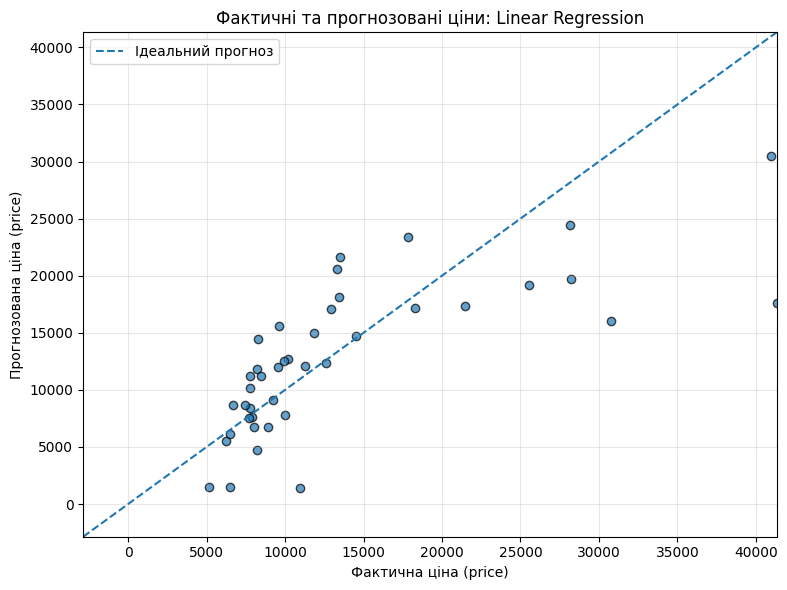

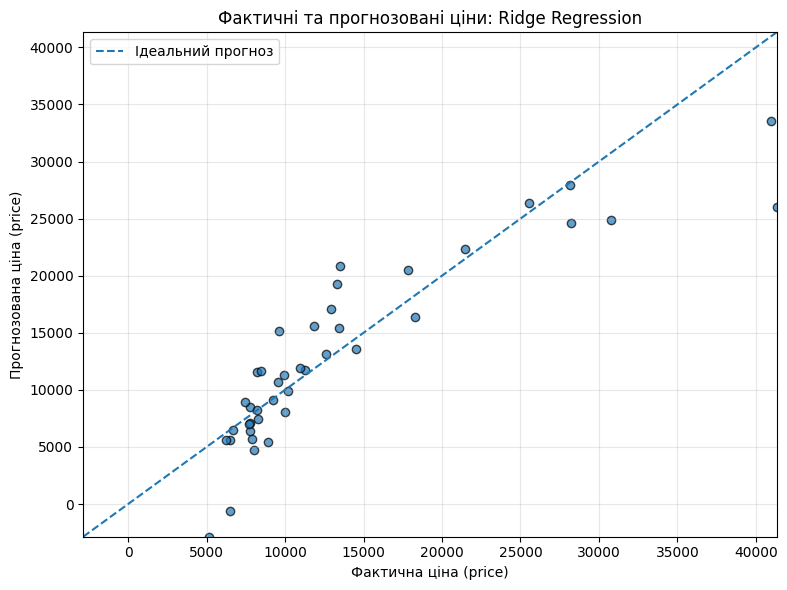

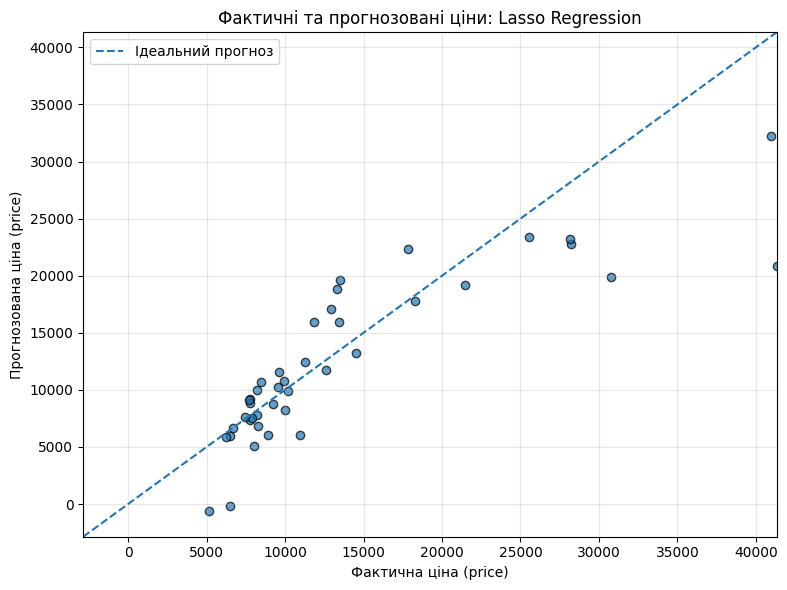

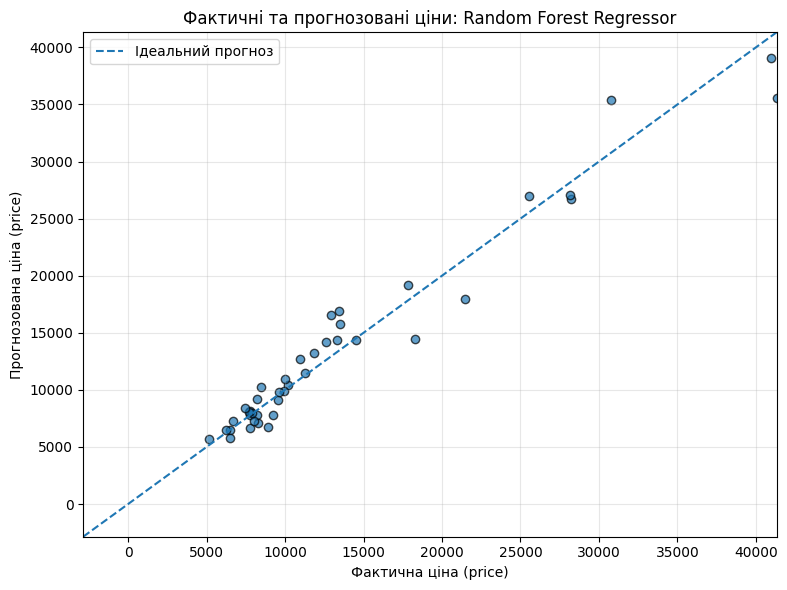

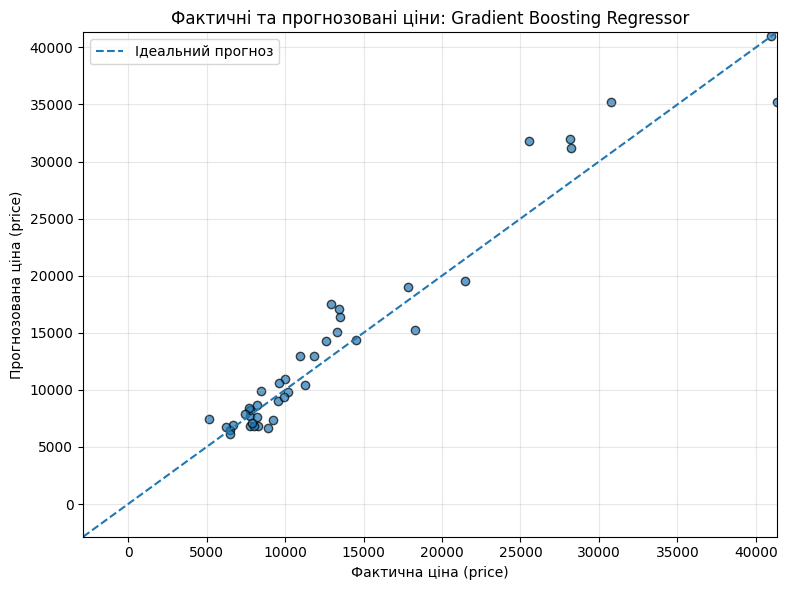

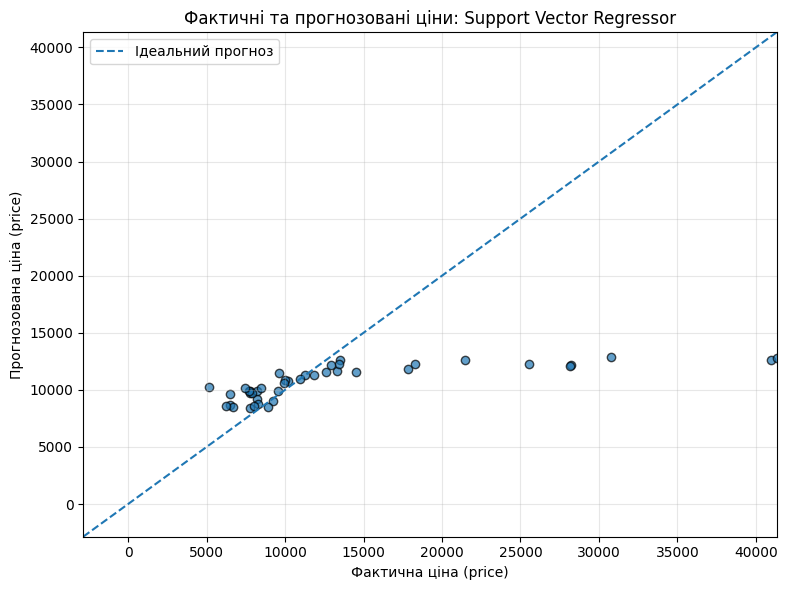

In [51]:
import matplotlib.pyplot as plt
import numpy as np

# Межі осей, однакові для всіх моделей
min_price = min(y_test.min(), min(pred.min() for pred in predictions.values()))
max_price = max(y_test.max(), max(pred.max() for pred in predictions.values()))

for name, y_pred in predictions.items():
    plt.figure(figsize=(8, 6))

    # Фактичні та прогнозовані ціни
    plt.scatter(y_test, y_pred, alpha=0.7, edgecolors="black")

    # Лінія ідеального прогнозу
    plt.plot(
        [min_price, max_price],
        [min_price, max_price],
        linestyle="--",
        label="Ідеальний прогноз"
    )

    plt.xlabel("Фактична ціна (price)")
    plt.ylabel("Прогнозована ціна (price)")
    plt.title(f"Фактичні та прогнозовані ціни: {name}")
    plt.xlim(min_price, max_price)
    plt.ylim(min_price, max_price)
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [52]:
for name, y_pred in predictions.items():
    comparison = pd.DataFrame({
        "Фактична ціна": y_test,
        "Прогнозована ціна": y_pred
    })

    comparison["Абсолютна помилка"] = (
        comparison["Фактична ціна"] -
        comparison["Прогнозована ціна"]
    ).abs()

    comparison["Помилка прогнозу"] = (
        comparison["Прогнозована ціна"] -
        comparison["Фактична ціна"]
    )

    print(f"\n{name} — 5 найбільших помилок:")

    display(
        comparison
        .sort_values("Абсолютна помилка", ascending=False)
        .head(5)
        .round(2)
    )


Linear Regression — 5 найбільших помилок:


,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Помилка прогнозу
16,41315.0,17619.65,23695.35,-23695.35
15,30760.0,16058.28,14701.72,-14701.72
73,40960.0,30488.26,10471.74,-10471.74
55,10945.0,1395.58,9549.42,-9549.42
68,28248.0,19740.58,8507.42,-8507.42



Ridge Regression — 5 найбільших помилок:


,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Помилка прогнозу
16,41315.0,26047.83,15267.17,-15267.17
18,5151.0,-2862.49,8013.49,-8013.49
73,40960.0,33562.35,7397.65,-7397.65
101,13499.0,20862.10,7363.10,7363.10
30,6479.0,-620.83,7099.83,-7099.83



Lasso Regression — 5 найбільших помилок:


,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Помилка прогнозу
16,41315.0,20844.83,20470.17,-20470.17
15,30760.0,19911.07,10848.93,-10848.93
73,40960.0,32199.40,8760.60,-8760.60
30,6479.0,-169.31,6648.31,-6648.31
101,13499.0,19633.66,6134.66,6134.66


... (2 outputs left out)


Gradient Boosting Regressor — 5 найбільших помилок:


,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Помилка прогнозу
67,25552.0,31835.83,6283.83,6283.83
16,41315.0,35182.76,6132.24,-6132.24
194,12940.0,17479.45,4539.45,4539.45
15,30760.0,35182.76,4422.76,4422.76
69,28176.0,32012.48,3836.48,3836.48



Support Vector Regressor — 5 найбільших помилок:


,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Помилка прогнозу
16,41315.0,12770.17,28544.83,-28544.83
73,40960.0,12584.04,28375.96,-28375.96
15,30760.0,12849.97,17910.03,-17910.03
68,28248.0,12184.39,16063.61,-16063.61
69,28176.0,12133.33,16042.67,-16042.67


In [53]:
for name, y_pred in predictions.items():
    absolute_errors = np.abs(np.asarray(y_test) - y_pred)

    print(
        f"{name}: "
        f"середня абсолютна помилка = {absolute_errors.mean():.2f}, "
        f"максимальна абсолютна помилка = {absolute_errors.max():.2f}"
    )

Linear Regression: середня абсолютна помилка = 4184.43, максимальна абсолютна помилка = 23695.35
Ridge Regression: середня абсолютна помилка = 2758.38, максимальна абсолютна помилка = 15267.17
Lasso Regression: середня абсолютна помилка = 3082.25, максимальна абсолютна помилка = 20470.17
Random Forest Regressor: середня абсолютна помилка = 1367.50, максимальна абсолютна помилка = 5765.25
Gradient Boosting Regressor: середня абсолютна помилка = 1660.09, максимальна абсолютна помилка = 6283.83
Support Vector Regressor: середня абсолютна помилка = 4549.10, максимальна абсолютна помилка = 28544.83


## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [56]:
import numpy as np

# Обираємо 10 випадкових індексів із тестової вибірки
sample_size = min(10, len(X_test))

sample_indices = X_test.sample(
    n=sample_size,
    random_state=42
).index

# Дані вибраних автомобілів
X_sample = X_test.loc[sample_indices]
y_actual = y_test.loc[sample_indices]

print(f"Вибрано автомобілів: {sample_size}")

Вибрано автомобілів: 10


In [57]:
# Отримуємо раніше навчений Pipeline Random Forest
rf_model = pipelines["Random Forest Regressor"]

# Прогнозуємо ціни
y_predicted = rf_model.predict(X_sample)

# Формуємо порівняльну таблицю
comparison_df = pd.DataFrame({
    "car_ID": car_ids.loc[sample_indices].values,
    "Фактична ціна": y_actual.values,
    "Прогнозована ціна": y_predicted
}, index=sample_indices)

# Обчислюємо помилки
comparison_df["Абсолютна помилка"] = (
    comparison_df["Фактична ціна"] -
    comparison_df["Прогнозована ціна"]
).abs()

comparison_df["Абсолютна відсоткова помилка (%)"] = (
    comparison_df["Абсолютна помилка"] /
    comparison_df["Фактична ціна"].abs()
) * 100

# Відображаємо результат
display(comparison_df.round(2))

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
25,26,6692.0,7242.46,550.45,8.23
175,176,9988.0,10928.84,940.84,9.42
147,148,10198.0,10466.21,268.21,2.63
16,17,41315.0,35549.75,5765.25,13.95
68,69,28248.0,26720.33,1527.67,5.41
146,147,7463.0,8405.92,942.92,12.63
143,144,9960.0,9898.08,61.92,0.62
84,85,14489.0,14408.73,80.27,0.55
194,195,12940.0,16551.88,3611.88,27.91
159,160,7788.0,7826.62,38.61,0.50


In [58]:
mean_abs_error = comparison_df["Абсолютна помилка"].mean()
mean_percentage_error = comparison_df[
    "Абсолютна відсоткова помилка (%)"
].mean()

max_error_row = comparison_df.loc[
    comparison_df["Абсолютна помилка"].idxmax()
]

min_error_row = comparison_df.loc[
    comparison_df["Абсолютна помилка"].idxmin()
]

print(f"Середня абсолютна помилка: {mean_abs_error:.2f}")
print(f"Середня абсолютна відсоткова помилка: {mean_percentage_error:.2f}%")

print("\nНайбільша абсолютна помилка:")
print(f"car_ID: {max_error_row['car_ID']}")
print(f"Фактична ціна: {max_error_row['Фактична ціна']:.2f}")
print(f"Прогнозована ціна: {max_error_row['Прогнозована ціна']:.2f}")
print(f"Абсолютна помилка: {max_error_row['Абсолютна помилка']:.2f}")

print("\nНайменша абсолютна помилка:")
print(f"car_ID: {min_error_row['car_ID']}")
print(f"Абсолютна помилка: {min_error_row['Абсолютна помилка']:.2f}")

Середня абсолютна помилка: 1378.80
Середня абсолютна відсоткова помилка: 8.19%

Найбільша абсолютна помилка:
car_ID: 17.0
Фактична ціна: 41315.00
Прогнозована ціна: 35549.75
Абсолютна помилка: 5765.25

Найменша абсолютна помилка:
car_ID: 160.0
Абсолютна помилка: 38.61


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


In [59]:
# Сортуємо моделі за R² від найбільшого до найменшого
final_results = results_df.sort_values(
    by="R²", ascending=False
).reset_index(drop=True)

display(final_results.round(4))

# Найкращі моделі за кожною метрикою
best_r2 = final_results.loc[final_results["R²"].idxmax()]
best_mae = final_results.loc[final_results["MAE"].idxmin()]
best_mse = final_results.loc[final_results["MSE"].idxmin()]
best_mape = final_results.loc[final_results["MAPE (%)"].idxmin()]

print("\nНайкращі результати за метриками:")
print(f"R²:   {best_r2['Модель']} ({best_r2['R²']:.4f})")
print(f"MAE:  {best_mae['Модель']} ({best_mae['MAE']:.4f})")
print(f"MSE:  {best_mse['Модель']} ({best_mse['MSE']:.4f})")
print(f"MAPE: {best_mape['Модель']} ({best_mape['MAPE (%)']:.2f}%)")

,Модель,R²,MAE,MSE,MAPE (%)
0,Random Forest Regressor,0.9538,1367.5006,3.648690e+06,9.9492
1,Gradient Boosting Regressor,0.9336,1660.0901,5.244394e+06,12.3659
2,Ridge Regression,0.7890,2758.3849,1.665988e+07,23.9112
3,Lasso Regression,0.7056,3082.2502,2.324487e+07,22.5790
4,Linear Regression,0.5298,4184.4319,3.711970e+07,30.6336
5,Support Vector Regressor,0.1086,4549.0959,7.036870e+07,25.5544



Найкращі результати за метриками:
R²:   Random Forest Regressor (0.9538)
MAE:  Random Forest Regressor (1367.5006)
MSE:  Random Forest Regressor (3648689.6930)
MAPE: Random Forest Regressor (9.95%)


In [60]:
print("АНАЛІЗ ЯКОСТІ МОДЕЛЕЙ\n")

for _, row in final_results.iterrows():
    print(
        f"{row['Модель']}: "
        f"R² = {row['R²']:.4f}; "
        f"MAE = {row['MAE']:.2f}; "
        f"MSE = {row['MSE']:.2f}; "
        f"MAPE = {row['MAPE (%)']:.2f}%"
    )

print("\nІнтерпретація:")
if best_r2["R²"] >= 0:
    print(
        f"Найкраща за R² модель — {best_r2['Модель']}. "
        "Вона має найбільше значення коефіцієнта детермінації."
    )
else:
    print(
        "Усі моделі мають від'ємний R². "
        "На тестових даних вони прогнозують гірше за простий прогноз "
        "середнім значенням фактичних цін."
    )

print(
    f"Найменшу середню абсолютну помилку має {best_mae['Модель']}, "
    f"а найменшу квадратичну помилку — {best_mse['Модель']}."
)

print(
    f"Найменшу середню абсолютну відсоткову помилку має "
    f"{best_mape['Модель']}."
)

АНАЛІЗ ЯКОСТІ МОДЕЛЕЙ

Random Forest Regressor: R² = 0.9538; MAE = 1367.50; MSE = 3648689.69; MAPE = 9.95%
Gradient Boosting Regressor: R² = 0.9336; MAE = 1660.09; MSE = 5244393.62; MAPE = 12.37%
Ridge Regression: R² = 0.7890; MAE = 2758.38; MSE = 16659876.13; MAPE = 23.91%
Lasso Regression: R² = 0.7056; MAE = 3082.25; MSE = 23244866.40; MAPE = 22.58%
Linear Regression: R² = 0.5298; MAE = 4184.43; MSE = 37119698.28; MAPE = 30.63%
Support Vector Regressor: R² = 0.1086; MAE = 4549.10; MSE = 70368700.00; MAPE = 25.55%

Інтерпретація:
Найкраща за R² модель — Random Forest Regressor. Вона має найбільше значення коефіцієнта детермінації.
Найменшу середню абсолютну помилку має Random Forest Regressor, а найменшу квадратичну помилку — Random Forest Regressor.
Найменшу середню абсолютну відсоткову помилку має Random Forest Regressor.


In [61]:
from sklearn.metrics import r2_score

overfitting_results = []

for name, pipeline in pipelines.items():
    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    r2_train = r2_score(y_train, train_pred)
    r2_test = r2_score(y_test, test_pred)

    overfitting_results.append({
        "Модель": name,
        "R² train": r2_train,
        "R² test": r2_test,
        "Різниця R² (train - test)": r2_train - r2_test
    })

overfitting_df = pd.DataFrame(overfitting_results).sort_values(
    "Різниця R² (train - test)", ascending=False
)

display(overfitting_df.round(4))

,Модель,R² train,R² test,Різниця R² (train - test)
0,Linear Regression,0.9930,0.5298,0.4632
2,Lasso Regression,0.9910,0.7056,0.2854
1,Ridge Regression,0.9627,0.7890,0.1737
4,Gradient Boosting Regressor,0.9915,0.9336,0.0579
3,Random Forest Regressor,0.9856,0.9538,0.0318
5,Support Vector Regressor,0.1215,0.1086,0.0128


In [62]:
print("Попередня обробка даних включала:")
print("1. Видалення ідентифікатора car_ID з ознак моделі.")
print("2. Обробку потенційних викидів методом IQR через обмеження значень.")
print("3. Усунення надмірно корельованих числових ознак.")
print("4. Трансформацію неперервних ознак методом Yeo–Johnson.")
print("5. Масштабування числових ознак.")
print("6. Кодування категоріальних ознак One-Hot Encoding.")
print(
    "\nОбробник навчався на тренувальній вибірці, "
    "а до тестової застосовувалися вже отримані перетворення."
)

Попередня обробка даних включала:
1. Видалення ідентифікатора car_ID з ознак моделі.
2. Обробку потенційних викидів методом IQR через обмеження значень.
3. Усунення надмірно корельованих числових ознак.
4. Трансформацію неперервних ознак методом Yeo–Johnson.
5. Масштабування числових ознак.
6. Кодування категоріальних ознак One-Hot Encoding.

Обробник навчався на тренувальній вибірці, а до тестової застосовувалися вже отримані перетворення.


## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
